In [1]:
import os

os.environ.setdefault(
    "CUBLAS_WORKSPACE_CONFIG",
    ":4096:8"
)

from pathlib import Path
from datetime import datetime

import sys
import json
import time
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch

from PIL import Image

In [2]:
PROJECT_DIR = Path(
    r"C:\Users\Joseph (YO)\JGM\U\Semestre_10\InteligenciaArtificial\Proyecto_Yuca"
)

DATASET_DIR = (
    PROJECT_DIR / "dataset" / "raw"
    / "cassava_dataset"
)

CONFIGS_DIR = PROJECT_DIR / "configs"
REPORTS_DIR = PROJECT_DIR / "reports"
EXPERIMENTS_DIR = PROJECT_DIR / "experiments"
DOCS_DIR = PROJECT_DIR / "docs"

RUN_ID = "final_evaluation_v1"

ENSEMBLE_REPORTS_DIR = (
    REPORTS_DIR / "ensemble"
    / "ensemble_cached_v1"
)

FINAL_REPORTS_DIR = (
    REPORTS_DIR / "final_evaluation"
    / RUN_ID
)

FINAL_EXPERIMENTS_DIR = (
    EXPERIMENTS_DIR / "final_evaluation"
    / RUN_ID
)

for directory in [
    DOCS_DIR,
    FINAL_REPORTS_DIR,
    FINAL_EXPERIMENTS_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

In [3]:
from src.utils import set_seed, get_device
from src.experiments import save_json

from src.inference import (
    read_json,
    CassavaInferenceEngine
)

from src.ensemble import (
    soft_voting,
    validate_probabilities
)

from src.metrics import calculate_metrics

dataset_config = read_json(
    CONFIGS_DIR / "dataset_config.json"
)

inference_config = read_json(
    CONFIGS_DIR / "inference_config.json"
)

SEED = dataset_config["seed"]
CLASS_MAPPING = dataset_config["class_mapping"]
ARCHITECTURES = inference_config["architectures"]

DEVICE = get_device()

set_seed(SEED)

print("Device:", DEVICE)
print("Architectures:", ARCHITECTURES)
print("Classes:", CLASS_MAPPING)

Device: cuda
Architectures: ['mobilenet_v3_large', 'efficientnet_b0', 'resnet50', 'vit_b_16', 'swin_t']
Classes: {'bacterial_blight': 0, 'brown_streak_disease': 1, 'green_mottle': 2, 'healthy': 3, 'mosaic_disease': 4}


In [4]:
required_files = {

    "dataset_splits":
        REPORTS_DIR / "dataset_splits.csv",

    "federated_splits":
        REPORTS_DIR / "federated_splits.csv",

    "dataset_config":
        CONFIGS_DIR / "dataset_config.json",

    "preprocessing_config":
        CONFIGS_DIR / "preprocessing_config.json",

    "centralized_registry":
        CONFIGS_DIR / "centralized_model_registry.json",

    "federated_registry":
        CONFIGS_DIR / "federated_model_registry.json",

    "ensemble_registry":
        CONFIGS_DIR / "ensemble_model_registry.json",

    "inference_config":
        CONFIGS_DIR / "inference_config.json",

    "final_test_results":
        ENSEMBLE_REPORTS_DIR / "all_test_results.csv",

    "ensemble_improvements":
        ENSEMBLE_REPORTS_DIR / "ensemble_improvements.csv",

    "class_level_results":
        ENSEMBLE_REPORTS_DIR / "class_level_results.csv",

    "computational_summary":
        ENSEMBLE_REPORTS_DIR / "computational_summary.json",

    "ensemble_summary":
        EXPERIMENTS_DIR / "ensemble"
        / "ensemble_cached_v1"
        / "ensemble_summary.json"

}

df_audit = pd.DataFrame([

    {
        "artifact": name,
        "path": str(path.relative_to(PROJECT_DIR)),
        "exists": path.exists()
    }

    for name, path in required_files.items()

])

display(df_audit)

df_audit.to_csv(
    FINAL_REPORTS_DIR / "artifact_audit.csv",
    index=False,
    encoding="utf-8-sig"
)

assert df_audit["exists"].all(), (
    "Existen entregables pendientes."
)

,artifact,path,exists
0,dataset_splits,reports\dataset_splits.csv,True
1,federated_splits,reports\federated_splits.csv,True
2,dataset_config,configs\dataset_config.json,True
3,preprocessing_config,configs\preprocessing_config.json,True
4,centralized_registry,configs\centralized_model_registry.json,True
5,federated_registry,configs\federated_model_registry.json,True
6,ensemble_registry,configs\ensemble_model_registry.json,True
7,inference_config,configs\inference_config.json,True
8,final_test_results,reports\ensemble\ensemble_cached_v1\all_test_r...,True
9,ensemble_improvements,reports\ensemble\ensemble_cached_v1\ensemble_i...,True


In [5]:
keywords = [
    "cross_validation",
    "hyperband",
    "baseline",
    "federated",
    "final_training"
]

available_reports = []

for path in REPORTS_DIR.rglob("*.csv"):

    relative_path = str(
        path.relative_to(PROJECT_DIR)
    )

    if any(
        keyword in relative_path.lower()
        for keyword in keywords
    ):
        available_reports.append({
            "filename": path.name,
            "path": relative_path
        })

df_available_reports = pd.DataFrame(
    available_reports
)

display(df_available_reports)

df_available_reports.to_csv(
    FINAL_REPORTS_DIR
    / "available_experimental_reports.csv",
    index=False,
    encoding="utf-8-sig"
)

,filename,path
0,federated_dataloader_summary.csv,reports\federated_dataloader_summary.csv
1,federated_file_integrity.csv,reports\federated_file_integrity.csv
2,federated_splits.csv,reports\federated_splits.csv
3,adamw_internal_steps_audit.csv,reports\baseline\baseline_v1\adamw_internal_st...
4,all_training_histories.csv,reports\baseline\baseline_v1\all_training_hist...
...,...,...
184,pruning_summary.csv,reports\hyperband\hyperband_v1\pruning_summary...
185,resnet50_trials.csv,reports\hyperband\hyperband_v1\resnet50_trials...
186,study_status.csv,reports\hyperband\hyperband_v1\study_status.csv
187,swin_t_trials.csv,reports\hyperband\hyperband_v1\swin_t_trials.csv


In [6]:
ensemble_summary = read_json(
    required_files["ensemble_summary"]
)

assert ensemble_summary["status"] == "completed"

assert ensemble_summary[
    "centralized_models_evaluated"
] == 5

assert ensemble_summary[
    "federated_models_evaluated"
] == 5

assert ensemble_summary[
    "total_evaluated_systems"
] == 12

assert ensemble_summary["test_images"] == 3210

assert not ensemble_summary[
    "test_used_for_training"
]

assert not ensemble_summary[
    "ensemble_weights_optimized"
]

display(ensemble_summary)

print("Fase 4 verificada.")

{'phase': 'phase_4',
 'experiment': 'ensemble_and_integration',
 'run_id': 'ensemble_cached_v1',
 'status': 'completed',
 'method': 'soft_voting',
 'weighting': 'uniform',
 'architectures': 5,
 'cnn_architectures': 3,
 'transformer_architectures': 2,
 'centralized_models_evaluated': 5,
 'federated_models_evaluated': 5,
 'centralized_ensembles': 1,
 'federated_ensembles': 1,
 'total_evaluated_systems': 12,
 'test_images': 3210,
 'primary_metric': 'f1_macro',
 'centralized_ensemble_f1': 0.6548510176536672,
 'federated_ensemble_f1': 0.638301890349369,
 'centralized_ensemble_accuracy': 0.7700934579439253,
 'federated_ensemble_accuracy': 0.7538940809968847,
 'shared_backbones_verified': 5,
 'test_feature_caches': 5,
 'integration_checks': 10,
 'integration_checks_passed': 10,
 'feature_caching': True,
 'new_training_performed': False,
 'ensemble_weights_optimized': False,
 'test_used': True,
 'test_used_for_training': False,
 'test_used_for_model_selection': False,
 'inference_engine_ready'

Fase 4 verificada.


In [7]:
from src.final_evaluation import (
    validate_final_results,
    compare_approaches,
    summarize_approaches
)

df_results = pd.read_csv(
    ENSEMBLE_REPORTS_DIR
    / "all_test_results.csv"
)

assert validate_final_results(
    df_results,
    ARCHITECTURES
)

df_results = df_results.sort_values(
    "f1_macro",
    ascending=False
).reset_index(drop=True)

display(df_results.round(4))

df_results.to_csv(
    FINAL_REPORTS_DIR
    / "final_model_ranking.csv",
    index=False,
    encoding="utf-8-sig"
)

,rank,model,approach,evaluation_split,num_samples,inference_seconds,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,balanced_accuracy,type
0,1,heterogeneous_ensemble,centralized,test,3210,0.0016,0.7701,0.6273,0.6983,0.6549,0.7799,0.6983,ensemble
1,2,heterogeneous_ensemble,federated,test,3210,0.0017,0.7539,0.6097,0.6799,0.6383,0.7652,0.6799,ensemble
2,3,swin_t,centralized,test,3210,0.0130,0.7312,0.5922,0.6837,0.6216,0.7464,0.6837,individual
3,4,swin_t,federated,test,3210,0.0099,0.7361,0.5919,0.6563,0.6183,0.7491,0.6563,individual
4,5,vit_b_16,federated,test,3210,0.0097,0.7212,0.5767,0.6433,0.6022,0.7353,0.6433,individual
5,6,vit_b_16,centralized,test,3210,0.0093,0.7109,0.5660,0.6539,0.5956,0.7284,0.6539,individual
6,7,resnet50,centralized,test,3210,0.0257,0.7199,0.5721,0.6272,0.5939,0.7345,0.6272,individual
7,8,resnet50,federated,test,3210,0.0256,0.7171,0.5664,0.6269,0.5898,0.7309,0.6269,individual
8,9,efficientnet_b0,federated,test,3210,0.0295,0.7062,0.5603,0.6274,0.5868,0.7220,0.6274,individual
9,10,mobilenet_v3_large,centralized,test,3210,0.1055,0.7137,0.5578,0.6298,0.5806,0.7304,0.6298,individual


In [8]:
df_comparison = compare_approaches(
    df_results
)

display(df_comparison.round(4))

df_comparison.to_csv(
    FINAL_REPORTS_DIR
    / "final_approach_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

,model,accuracy_centralized,precision_macro_centralized,recall_macro_centralized,f1_macro_centralized,f1_weighted_centralized,accuracy_federated,precision_macro_federated,recall_macro_federated,f1_macro_federated,f1_weighted_federated,accuracy_difference_pp,precision_macro_difference_pp,recall_macro_difference_pp,f1_macro_difference_pp,f1_weighted_difference_pp
0,heterogeneous_ensemble,0.7701,0.6273,0.6983,0.6549,0.7799,0.7539,0.6097,0.6799,0.6383,0.7652,-1.6199,-1.7631,-1.8379,-1.6549,-1.4686
1,swin_t,0.7312,0.5922,0.6837,0.6216,0.7464,0.7361,0.5919,0.6563,0.6183,0.7491,0.4984,-0.0319,-2.7405,-0.3302,0.2725
2,vit_b_16,0.7109,0.5660,0.6539,0.5956,0.7284,0.7212,0.5767,0.6433,0.6022,0.7353,1.0280,1.0730,-1.0594,0.6694,0.6952
3,resnet50,0.7199,0.5721,0.6272,0.5939,0.7345,0.7171,0.5664,0.6269,0.5898,0.7309,-0.2804,-0.5692,-0.0270,-0.4004,-0.3605
4,mobilenet_v3_large,0.7137,0.5578,0.6298,0.5806,0.7304,0.6629,0.5230,0.6210,0.5492,0.6896,-5.0779,-3.4838,-0.8783,-3.1395,-4.0774
5,efficientnet_b0,0.7037,0.5526,0.6256,0.5771,0.7196,0.7062,0.5603,0.6274,0.5868,0.7220,0.2492,0.7752,0.1804,0.9699,0.2446


In [9]:
df_approach_summary = summarize_approaches(
    df_results
)

display(df_approach_summary.round(4))

df_approach_summary.to_csv(
    FINAL_REPORTS_DIR
    / "final_ensemble_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

,approach,best_individual_model,best_individual_f1,mean_individual_f1,ensemble_f1,ensemble_accuracy,ensemble_gain_pp
0,centralized,swin_t,0.6216,0.5937,0.6549,0.7701,3.3213
1,federated,swin_t,0.6183,0.5893,0.6383,0.7539,1.9966


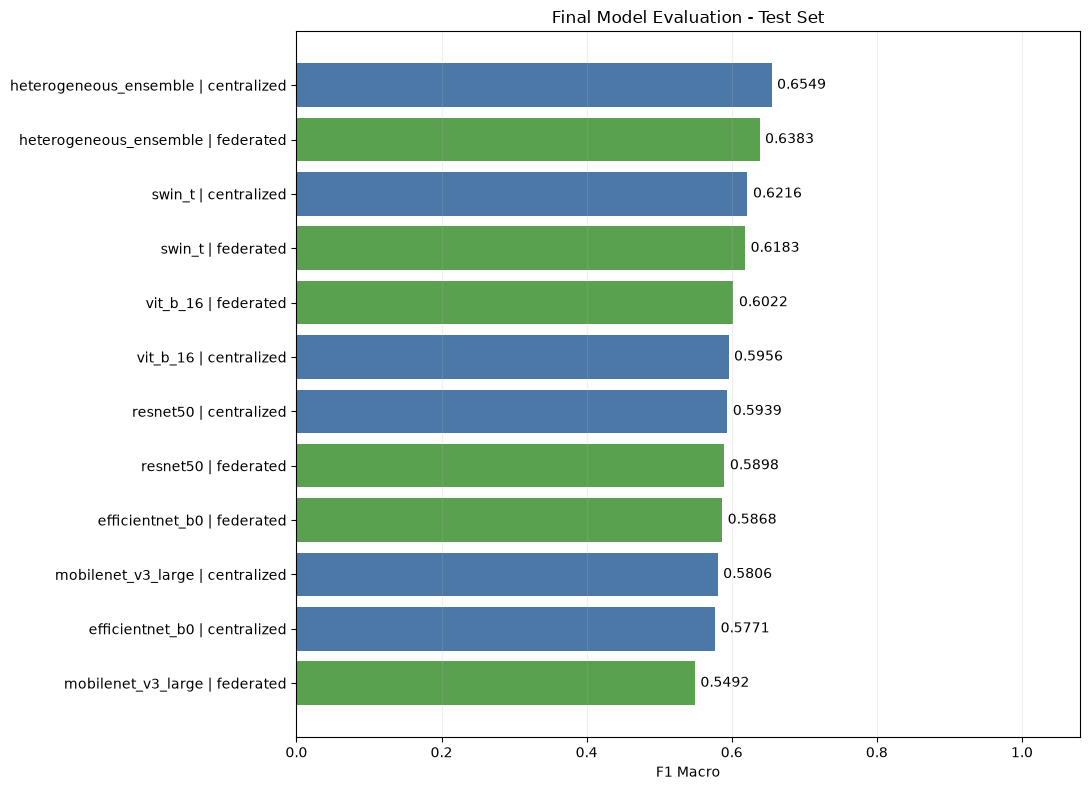

In [10]:
df_plot = df_results.copy()

df_plot["label"] = (

    df_plot["model"]

    + " | "

    + df_plot["approach"]

)

df_plot = df_plot.sort_values(
    "f1_macro"
)

colors = [
    "#4C78A8" if approach == "centralized"
    else "#59A14F"

    for approach in df_plot["approach"]
]

fig, ax = plt.subplots(figsize=(11, 8))

bars = ax.barh(
    df_plot["label"],
    df_plot["f1_macro"],
    color=colors
)

ax.bar_label(
    bars,
    fmt="%.4f",
    padding=4
)

ax.set_xlim(0, 1.08)
ax.set_xlabel("F1 Macro")
ax.set_title("Final Model Evaluation - Test Set")

plt.grid(axis="x", alpha=0.2)
plt.tight_layout()

plt.savefig(
    FINAL_REPORTS_DIR
    / "final_model_ranking.png",
    dpi=150
)

plt.show()

In [11]:
df_splits = pd.read_csv(
    REPORTS_DIR / "dataset_splits.csv"
)

df_development = df_splits[
    df_splits["split"] == "development"
].reset_index(drop=True)

df_test = df_splits[
    df_splits["split"] == "test"
].reset_index(drop=True)

majority_class = (
    df_development["class"]
    .value_counts()
    .idxmax()
)

y_true = df_test["class"].map(
    CLASS_MAPPING
).to_numpy()

y_pred = np.full(
    len(df_test),
    CLASS_MAPPING[majority_class]
)

naive_metrics = calculate_metrics(
    y_true,
    y_pred,
    len(CLASS_MAPPING)
)

naive_result = {
    "model": "majority_class_baseline",
    "majority_class": majority_class,
    **naive_metrics
}

save_json(
    naive_result,
    FINAL_REPORTS_DIR
    / "majority_baseline.json"
)

display(naive_result)

{'model': 'majority_class_baseline',
 'majority_class': 'mosaic_disease',
 'accuracy': 0.6149532710280374,
 'precision_macro': 0.12299065420560748,
 'recall_macro': 0.2,
 'f1_macro': 0.15231481481481482,
 'f1_weighted': 0.4683324679820007,
 'balanced_accuracy': 0.2}

In [12]:
df_results["gain_vs_naive_f1_pp"] = (

    df_results["f1_macro"]

    - naive_metrics["f1_macro"]

) * 100

display(

    df_results[[
        "model",
        "approach",
        "f1_macro",
        "gain_vs_naive_f1_pp"
    ]].round(4)

)

df_results.to_csv(
    FINAL_REPORTS_DIR
    / "final_results_with_baseline.csv",
    index=False,
    encoding="utf-8-sig"
)

,model,approach,f1_macro,gain_vs_naive_f1_pp
0,heterogeneous_ensemble,centralized,0.6549,50.2536
1,heterogeneous_ensemble,federated,0.6383,48.5987
2,swin_t,centralized,0.6216,46.9323
3,swin_t,federated,0.6183,46.6021
4,vit_b_16,federated,0.6022,44.9935
5,vit_b_16,centralized,0.5956,44.3241
6,resnet50,centralized,0.5939,44.1537
7,resnet50,federated,0.5898,43.7533
8,efficientnet_b0,federated,0.5868,43.4452
9,mobilenet_v3_large,centralized,0.5806,42.8250


In [13]:
CV_RESULTS_PATH = Path(
    input("Ruta del CSV de validación cruzada: ")
    .strip()
    .strip('"')
)

if not CV_RESULTS_PATH.is_absolute():
    CV_RESULTS_PATH = (
        PROJECT_DIR / CV_RESULTS_PATH
    )

df_cv = pd.read_csv(CV_RESULTS_PATH)

display(df_cv.head())

print(df_cv.columns.tolist())

,architecture,family,fold,best_epoch,epochs_completed,train_images,validation_images,hyperparameter_source,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,balanced_accuracy,loss,seconds,num_samples,total_seconds,total_minutes,status
0,mobilenet_v3_large,CNN,1,2,3,12124,6063,hyperband_feature_extraction,0.720106,0.571428,0.613133,0.586278,0.732977,0.613133,0.988865,0.111733,6063,5.180306,0.086338,success
1,mobilenet_v3_large,CNN,2,3,3,12125,6062,hyperband_feature_extraction,0.709832,0.557680,0.635839,0.586390,0.726308,0.635839,0.947854,0.120457,6062,5.048350,0.084139,success
2,mobilenet_v3_large,CNN,3,2,3,12125,6062,hyperband_feature_extraction,0.700264,0.567190,0.622324,0.581547,0.717744,0.622324,0.976545,0.117448,6062,4.368447,0.072807,success
3,efficientnet_b0,CNN,1,3,3,12124,6063,baseline_feature_extraction,0.718786,0.571231,0.629405,0.586798,0.732368,0.629405,0.962638,0.144130,6063,3.443452,0.057391,success
4,efficientnet_b0,CNN,2,2,3,12125,6062,baseline_feature_extraction,0.717090,0.568426,0.631650,0.591637,0.730211,0.631650,0.966339,0.154811,6062,4.135846,0.068931,success


['architecture', 'family', 'fold', 'best_epoch', 'epochs_completed', 'train_images', 'validation_images', 'hyperparameter_source', 'accuracy', 'precision_macro', 'recall_macro', 'f1_macro', 'f1_weighted', 'balanced_accuracy', 'loss', 'seconds', 'num_samples', 'total_seconds', 'total_minutes', 'status']


In [14]:
assert set(df_cv["architecture"]) == set(
    ARCHITECTURES
)

assert not df_cv.duplicated(
    subset=["architecture", "fold"]
).any()

assert df_cv.groupby(
    "architecture"
)["fold"].apply(
    lambda x: set(x) == {1, 2, 3}
).all()

df_cv_summary = (

    df_cv.groupby("architecture")

    .agg(
        folds=("fold", "nunique"),
        f1_macro_mean=("f1_macro", "mean"),
        f1_macro_std=("f1_macro", "std"),
        f1_macro_min=("f1_macro", "min"),
        f1_macro_max=("f1_macro", "max")
    )

    .reset_index()

)

display(df_cv_summary.round(4))

df_cv_summary.to_csv(
    FINAL_REPORTS_DIR
    / "cross_validation_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

,architecture,folds,f1_macro_mean,f1_macro_std,f1_macro_min,f1_macro_max
0,efficientnet_b0,3,0.5869,0.0046,0.5824,0.5916
1,mobilenet_v3_large,3,0.5847,0.0028,0.5815,0.5864
2,resnet50,3,0.5789,0.0074,0.5737,0.5874
3,swin_t,3,0.6212,0.0112,0.6084,0.6291
4,vit_b_16,3,0.5816,0.0038,0.5783,0.5858


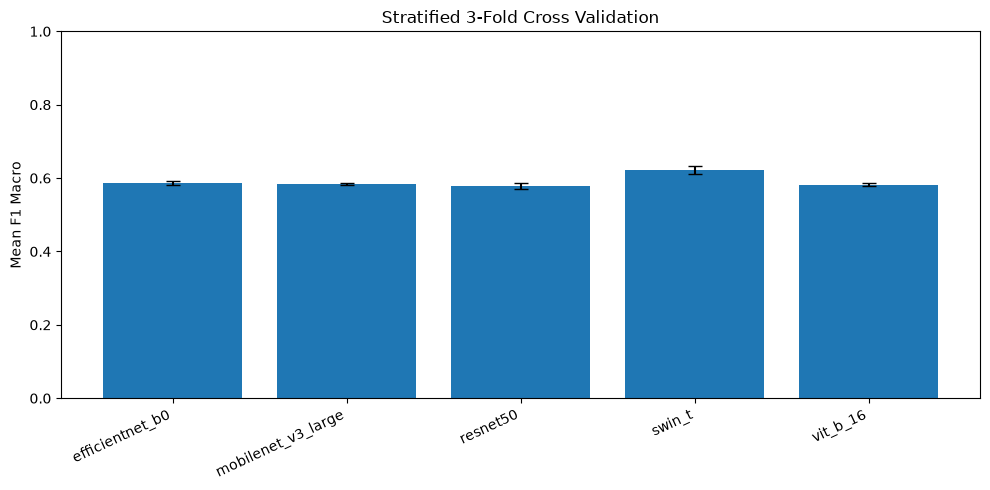

In [15]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(

    df_cv_summary["architecture"],

    df_cv_summary["f1_macro_mean"],

    yerr=df_cv_summary["f1_macro_std"],

    capsize=5

)

ax.set_ylabel("Mean F1 Macro")
ax.set_title("Stratified 3-Fold Cross Validation")
ax.set_ylim(0, 1)

plt.xticks(rotation=25, ha="right")
plt.tight_layout()

plt.savefig(
    FINAL_REPORTS_DIR
    / "cross_validation_stability.png",
    dpi=150
)

plt.show()

In [16]:
df_federated = pd.read_csv(
    REPORTS_DIR / "federated_splits.csv"
)

df_clients = df_federated[
    df_federated["split"] == "development"
]

assert set(df_clients["client_id"]) == {1, 2}

assert (

    df_federated[
        df_federated["split"] == "test"
    ]["client_id"] == -1

).all()

df_client_distribution = pd.crosstab(

    df_clients["class"],

    df_clients["client_id"],

    margins=True

)

display(df_client_distribution)

df_client_distribution.to_csv(
    FINAL_REPORTS_DIR
    / "federated_client_distribution.csv",
    encoding="utf-8-sig"
)

client_id,1,2,All
class,,,
bacterial_blight,462,462,924
brown_streak_disease,930,931,1861
green_mottle,1014,1014,2028
healthy,1095,1095,2190
mosaic_disease,5592,5592,11184
All,9093,9094,18187


In [18]:
FED_HISTORY_PATH = Path(
    input("Ruta del CSV de rondas federadas: ")
    .strip()
    .strip('"')
)

if not FED_HISTORY_PATH.is_absolute():
    FED_HISTORY_PATH = (
        PROJECT_DIR / FED_HISTORY_PATH
    )

df_fed_history = pd.read_csv(
    FED_HISTORY_PATH
)

display(df_fed_history.head())

print(df_fed_history.columns.tolist())

,architecture,stage,round,participating_clients,training_samples,global_update_norm,client_1_samples,client_1_weight,client_1_update_norm,client_2_samples,...,val_precision_macro,val_recall_macro,val_f1_macro,val_f1_weighted,val_balanced_accuracy,val_loss,val_seconds,val_num_samples,round_seconds,fold
0,mobilenet_v3_large,validation,1,2,12124,10.245501,6062,0.5,12.009744,6062,...,0.529641,0.598926,0.549059,0.685164,0.598926,1.007259,0.144138,6063,2.312119,1
1,mobilenet_v3_large,validation,2,2,12124,6.687776,6062,0.5,8.997320,6062,...,0.519751,0.615239,0.544992,0.674494,0.615239,0.980384,0.153727,6063,2.016241,1
2,mobilenet_v3_large,validation,3,2,12124,5.854751,6062,0.5,8.412847,6062,...,0.564718,0.635954,0.586349,0.734035,0.635954,0.950967,0.126484,6063,1.785615,1
3,efficientnet_b0,validation,1,2,12124,1.564907,6062,0.5,1.684025,6062,...,0.501740,0.572980,0.518913,0.679652,0.572980,1.073364,0.205490,6063,2.049826,1
4,efficientnet_b0,validation,2,2,12124,0.863224,6062,0.5,1.057897,6062,...,0.512949,0.600533,0.541202,0.678051,0.600533,1.013644,0.219123,6063,2.193966,1


['architecture', 'stage', 'round', 'participating_clients', 'training_samples', 'global_update_norm', 'client_1_samples', 'client_1_weight', 'client_1_update_norm', 'client_2_samples', 'client_2_weight', 'client_2_update_norm', 'val_accuracy', 'val_precision_macro', 'val_recall_macro', 'val_f1_macro', 'val_f1_weighted', 'val_balanced_accuracy', 'val_loss', 'val_seconds', 'val_num_samples', 'round_seconds', 'fold']


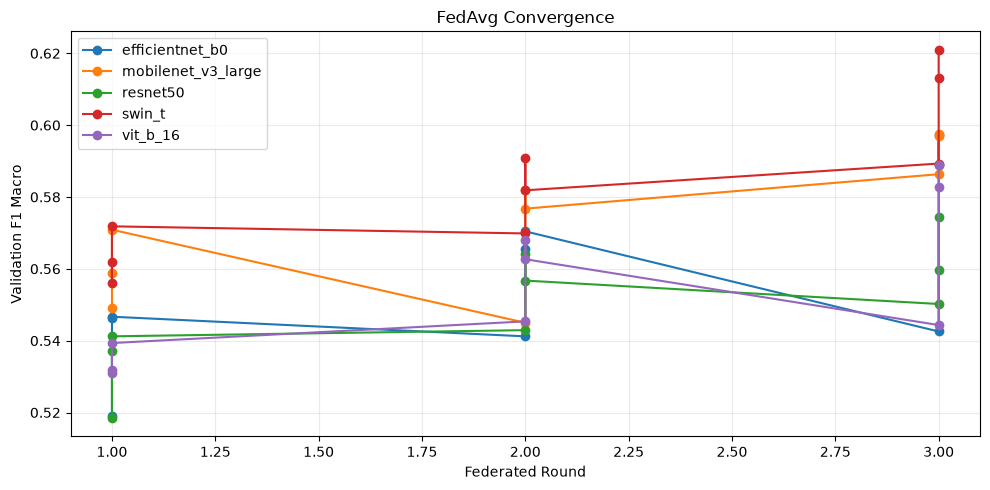

In [19]:
fig, ax = plt.subplots(figsize=(10, 5))

for architecture, group in (
    df_fed_history.groupby("architecture")
):

    group = group.sort_values("round")

    ax.plot(
        group["round"],
        group["val_f1_macro"],
        marker="o",
        label=architecture
    )

ax.set_xlabel("Federated Round")
ax.set_ylabel("Validation F1 Macro")
ax.set_title("FedAvg Convergence")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    FINAL_REPORTS_DIR
    / "federated_convergence.png",
    dpi=150
)

plt.show()

In [20]:
compute_summary = read_json(
    ENSEMBLE_REPORTS_DIR
    / "computational_summary.json"
)

df_compute = pd.DataFrame([

    {
        "operation": "Feature extraction",
        "seconds": compute_summary[
            "feature_extraction_seconds"
        ]
    },

    {
        "operation": "Classifier inference",
        "seconds": compute_summary[
            "classifier_inference_seconds"
        ]
    },

    {
        "operation": "Soft Voting",
        "seconds": compute_summary[
            "soft_voting_seconds"
        ]
    }

])

df_compute["minutes"] = (
    df_compute["seconds"] / 60
)

display(df_compute.round(4))

df_compute.to_csv(
    FINAL_REPORTS_DIR
    / "computational_costs.csv",
    index=False,
    encoding="utf-8-sig"
)

,operation,seconds,minutes
0,Feature extraction,256.9960,4.2833
1,Classifier inference,0.3026,0.0050
2,Soft Voting,0.0033,0.0001


In [21]:
engine = CassavaInferenceEngine(

    project_dir=PROJECT_DIR,

    device=DEVICE

)

print("Inference engine ready.")

Inference engine ready.


In [22]:
df_functional_samples = (

    df_development.groupby(

        "class",

        group_keys=False

    ).sample(

        n=1,

        random_state=SEED

    ).reset_index(drop=True)

)

assert len(df_functional_samples) == 5

display(

    df_functional_samples[[
        "filepath",
        "class"
    ]]

)

,filepath,class
0,bacterial_blight\4156138691.jpg,bacterial_blight
1,brown_streak_disease\4019472268.jpg,brown_streak_disease
2,green_mottle\1803483476.jpg,green_mottle
3,healthy\3151081789.jpg,healthy
4,mosaic_disease\3688529022.jpg,mosaic_disease


In [23]:
functional_results = []

for _, row in df_functional_samples.iterrows():

    image_path = (
        DATASET_DIR / row["filepath"]
    )

    with Image.open(image_path) as original:
        image = original.copy()

    prediction = engine.predict(

        image=image,

        approach="both",

        model_name="ensemble"

    )

    for approach, result in (
        prediction["results"].items()
    ):

        individual = result[
            "individual_predictions"
        ]

        assert set(individual) == set(
            ARCHITECTURES
        )

        systems = {

            **individual,

            "heterogeneous_ensemble": result

        }

        for model_name, model_result in (
            systems.items()
        ):

            probabilities = np.array([

                model_result["probabilities"][c]

                for c in engine.class_names

            ])

            valid = bool(

                len(probabilities) == 5

                and np.isfinite(
                    probabilities
                ).all()

                and (probabilities >= 0).all()

                and (probabilities <= 1).all()

                and np.isclose(
                    probabilities.sum(),
                    1.0,
                    atol=1e-5
                )

                and model_result[
                    "predicted_index"
                ] == probabilities.argmax()

                and model_result[
                    "predicted_class"
                ] == engine.class_names[
                    probabilities.argmax()
                ]

            )

            functional_results.append({

                "filepath": row["filepath"],

                "real_class": row["class"],

                "model": model_name,

                "approach": approach,

                "predicted_class":

                    model_result["predicted_class"],

                "confidence":

                    model_result["confidence"],

                "functional_test_passed": valid

            })

    print(
        row["class"],
        "| Functional inference completed"
    )

df_functional = pd.DataFrame(
    functional_results
)

display(df_functional)

assert len(df_functional) == 60

assert df_functional[
    "functional_test_passed"
].all()

df_functional.to_csv(

    FINAL_REPORTS_DIR
    / "functional_inference_tests.csv",

    index=False,

    encoding="utf-8-sig"

)

engine.unload()

bacterial_blight | Functional inference completed
brown_streak_disease | Functional inference completed
green_mottle | Functional inference completed
healthy | Functional inference completed
mosaic_disease | Functional inference completed


,filepath,real_class,model,approach,predicted_class,confidence,functional_test_passed
0,bacterial_blight\4156138691.jpg,bacterial_blight,mobilenet_v3_large,centralized,healthy,0.538631,True
1,bacterial_blight\4156138691.jpg,bacterial_blight,efficientnet_b0,centralized,healthy,0.649903,True
2,bacterial_blight\4156138691.jpg,bacterial_blight,resnet50,centralized,bacterial_blight,0.331769,True
3,bacterial_blight\4156138691.jpg,bacterial_blight,vit_b_16,centralized,healthy,0.649610,True
4,bacterial_blight\4156138691.jpg,bacterial_blight,swin_t,centralized,healthy,0.619656,True
5,bacterial_blight\4156138691.jpg,bacterial_blight,heterogeneous_ensemble,centralized,healthy,0.545934,True
6,bacterial_blight\4156138691.jpg,bacterial_blight,mobilenet_v3_large,federated,bacterial_blight,0.476495,True
7,bacterial_blight\4156138691.jpg,bacterial_blight,efficientnet_b0,federated,healthy,0.555093,True
8,bacterial_blight\4156138691.jpg,bacterial_blight,resnet50,federated,bacterial_blight,0.405677,True
9,bacterial_blight\4156138691.jpg,bacterial_blight,vit_b_16,federated,healthy,0.503207,True


In [24]:
sample_path = (

    DATASET_DIR

    / df_functional_samples.iloc[0]["filepath"]

)

with Image.open(sample_path) as original:
    sample_image = original.copy()

latency_results = []

for model_name in [
    "mobilenet_v3_large",
    "ensemble"
]:

    engine.unload()

    for repetition in range(1, 4):

        start = time.perf_counter()

        result = engine.predict(

            image=sample_image,

            approach="both",

            model_name=model_name

        )

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()

        latency_results.append({

            "model": model_name,

            "repetition": repetition,

            "seconds": time.perf_counter() - start

        })

df_latency = pd.DataFrame(
    latency_results
)

display(df_latency.round(4))

df_latency.to_csv(

    FINAL_REPORTS_DIR
    / "inference_latency.csv",

    index=False,

    encoding="utf-8-sig"

)

engine.unload()

,model,repetition,seconds
0,mobilenet_v3_large,1,0.7098
1,mobilenet_v3_large,2,0.0264
2,mobilenet_v3_large,3,0.0315
3,ensemble,1,7.7949
4,ensemble,2,6.9558
5,ensemble,3,6.8063


In [25]:
def dataframe_to_markdown(dataframe):

    columns = dataframe.columns.tolist()

    lines = [

        "| " + " | ".join(
            map(str, columns)
        ) + " |",

        "| " + " | ".join(
            ["---"] * len(columns)
        ) + " |"

    ]

    for row in dataframe.itertuples(
        index=False,
        name=None
    ):

        values = [

            f"{value:.4f}"

            if isinstance(
                value,
                (float, np.floating)
            )

            else str(value)

            for value in row

        ]

        lines.append(
            "| " + " | ".join(values) + " |"
        )

    return "\n".join(lines)

In [26]:
ranking_table = dataframe_to_markdown(

    df_results[[

        "model",

        "approach",

        "accuracy",

        "precision_macro",

        "recall_macro",

        "f1_macro"

    ]]

)

cv_table = dataframe_to_markdown(
    df_cv_summary
)

ensemble_table = dataframe_to_markdown(
    df_approach_summary
)

federated_table = dataframe_to_markdown(
    df_client_distribution.reset_index()
)

technical_documentation = f"""
# Documentación técnica - Cassava AI

## 1. Descripción del proyecto

Sistema de clasificación de enfermedades de
hojas de yuca mediante aprendizaje profundo,
aprendizaje federado y ensembles heterogéneos.

## 2. Dataset

- Total de imágenes: {len(df_splits)}
- Desarrollo: {len(df_development)}
- Test independiente: {len(df_test)}
- Número de clases: {len(CLASS_MAPPING)}
- Semilla experimental: {SEED}

La partición se realizó de forma estratificada.

## 3. Preprocesamiento

- Conversión a RGB.
- Corrección de orientación EXIF.
- Redimensionamiento a 224 x 224.
- Normalización ImageNet.

En la versión optimizada mediante Feature
Caching se utilizaron características
precalculadas de extractores congelados.

## 4. Arquitecturas

- MobileNetV3-Large.
- EfficientNet-B0.
- ResNet50.
- Vision Transformer B/16.
- Swin Transformer Tiny.

## 5. Optimización de hiperparámetros

Se utilizó Optuna con Hyperband y un presupuesto
reducido de búsqueda para limitar el costo
computacional.

Los presupuestos efectivos y configuraciones
seleccionadas se conservan en los registros
experimentales.

## 6. Validación cruzada

Se utilizaron tres folds estratificados.

{cv_table}

## 7. Aprendizaje federado

Se utilizó una simulación con un servidor
central y dos clientes con distribución
aproximadamente IID.

El algoritmo de agregación fue FedAvg.

### Distribución de clientes

{federated_table}

## 8. Ensemble heterogéneo

Se implementaron dos ensembles independientes:

- Ensemble centralizado.
- Ensemble federado.

Cada ensemble combina cinco arquitecturas
mediante Soft Voting con pesos uniformes.

## 9. Evaluación final

La métrica principal es F1 Macro debido
al desbalance entre clases.

{ranking_table}

## 10. Comparación de ensembles

{ensemble_table}

## 11. Optimización computacional

Se reutilizaron características de extractores
congelados para reducir operaciones repetidas.

La evaluación compartida centralizada y federada
evitó duplicar la extracción de características
cuando los backbones eran idénticos.

## 12. Producto

La aplicación utiliza Streamlit como interfaz
y CassavaInferenceEngine como motor de inferencia.

Permite seleccionar modelos individuales,
ensembles y enfoques de aprendizaje.

## 13. Limitaciones

- Dataset desbalanceado.
- Aprendizaje federado simulado.
- Distribución aproximadamente IID.
- Probabilidades no calibradas.
- Presupuesto reducido de hiperparámetros.
- No se implementó detección fuera del dominio.
- No se realizó validación externa en campo.
- La validación cruzada no fue anidada.
- Feature Caching limita el ajuste del backbone.

## 14. Reproducibilidad

Se conservaron configuraciones JSON, particiones
CSV, checkpoints, semillas, historiales y
registros experimentales.

Fecha de generación:
{datetime.now().isoformat()}
"""

(DOCS_DIR / "technical_documentation.md").write_text(

    technical_documentation,

    encoding="utf-8"

)

print("Documentación técnica generada.")

Documentación técnica generada.


In [29]:
def calculate_file_hash(filepath):

    sha256 = hashlib.sha256()

    with open(filepath, "rb") as file:

        for chunk in iter(

            lambda: file.read(1024 * 1024),

            b""

        ):

            sha256.update(chunk)

    return sha256.hexdigest()


delivery_files = [

    PROJECT_DIR / "app.py",

    PROJECT_DIR / "README.md",

    PROJECT_DIR / "requirements.txt",

    DOCS_DIR / "technical_documentation.md",

    DOCS_DIR / "user_manual.md",

    DOCS_DIR / "model_card.md",

    REPORTS_DIR / "dataset_splits.csv",

    REPORTS_DIR / "federated_splits.csv"

]

delivery_files.extend(
    CONFIGS_DIR.glob("*.json")
)

delivery_files.extend(
    (PROJECT_DIR / "src").glob("*.py")
)

for registry_name in [

    "centralized_model_registry.json",

    "federated_model_registry.json"

]:

    registry = read_json(
        CONFIGS_DIR / registry_name
    )

    for model_info in registry["models"].values():

        delivery_files.append(

            PROJECT_DIR / model_info["model_path"]

        )

        if "classifier_path" in model_info:

            delivery_files.append(

                PROJECT_DIR
                / model_info["classifier_path"]

            )

delivery_files.extend(

    FINAL_REPORTS_DIR.glob("*.csv")

)

delivery_files.extend(

    ENSEMBLE_REPORTS_DIR.rglob("*.csv")

)

delivery_files = sorted(
    set(delivery_files)
)

manifest = []

for filepath in delivery_files:

    assert filepath.exists(), (
        f"Missing: {filepath}"
    )

    manifest.append({

        "filepath": str(
            filepath.relative_to(PROJECT_DIR)
        ),

        "size_bytes":
            filepath.stat().st_size,

        "sha256":
            calculate_file_hash(filepath)

    })

df_manifest = pd.DataFrame(manifest)

df_manifest.to_csv(

    FINAL_EXPERIMENTS_DIR
    / "delivery_manifest.csv",

    index=False,

    encoding="utf-8-sig"

)

print(
    "Verified files:",
    len(df_manifest)
)

Verified files: 123


In [33]:
assert (
    DOCS_DIR / "model_card.md"
).exists()

ui_tests_path = (

    FINAL_REPORTS_DIR

    / "ui_acceptance_tests.csv"

)

assert ui_tests_path.exists(), (
    "Falta el registro de pruebas manuales."
)

df_ui_tests = pd.read_csv(ui_tests_path)

assert len(df_ui_tests) == 15

assert df_ui_tests["Prueba"].is_unique

assert (
    df_ui_tests["Estado"] == "PASS"
).all()

print(
    "Verificaciones finales superadas."
)

Verificaciones finales superadas.


In [34]:
best_test_result = df_results.loc[

    df_results["f1_macro"].idxmax()

]

final_summary = {

    "project": "Cassava AI",

    "phase": "phase_5",

    "run_id": RUN_ID,

    "status": "completed",

    "dataset_images": len(df_splits),

    "development_images": len(df_development),

    "test_images": len(df_test),

    "num_classes": len(CLASS_MAPPING),

    "architectures": 5,

    "cnn_architectures": 3,

    "transformer_architectures": 2,

    "cross_validation_folds": 3,

    "centralized_models": 5,

    "federated_models": 5,

    "federated_servers": 1,

    "federated_clients": 2,

    "federated_algorithm": "FedAvg",

    "federated_simulation": True,

    "ensembles": 2,

    "ensemble_method": "Soft Voting",

    "evaluated_systems": 12,

    "primary_metric": "f1_macro",

    "highest_observed_test_f1": float(

        best_test_result["f1_macro"]

    ),

    "highest_observed_test_model":

        best_test_result["model"],

    "highest_observed_test_approach":

        best_test_result["approach"],

    "functional_tests": len(df_functional),

    "functional_tests_passed": int(

        df_functional[
            "functional_test_passed"
        ].sum()

    ),

    "ui_tests_passed": len(df_ui_tests),

    "application": "Streamlit",

    "documentation_completed": True,

    "delivery_files_verified": len(df_manifest),

    "additional_training_performed": False,

    "timestamp": datetime.now().isoformat()

}

save_json(

    final_summary,

    FINAL_EXPERIMENTS_DIR

    / "project_final_summary.json"

)

display(final_summary)

print("=" * 65)

print("PROYECTO CASSAVA AI COMPLETADO")

print("=" * 65)

{'project': 'Cassava AI',
 'phase': 'phase_5',
 'run_id': 'final_evaluation_v1',
 'status': 'completed',
 'dataset_images': 21397,
 'development_images': 18187,
 'test_images': 3210,
 'num_classes': 5,
 'architectures': 5,
 'cnn_architectures': 3,
 'transformer_architectures': 2,
 'cross_validation_folds': 3,
 'centralized_models': 5,
 'federated_models': 5,
 'federated_servers': 1,
 'federated_clients': 2,
 'federated_algorithm': 'FedAvg',
 'federated_simulation': True,
 'ensembles': 2,
 'ensemble_method': 'Soft Voting',
 'evaluated_systems': 12,
 'primary_metric': 'f1_macro',
 'highest_observed_test_f1': 0.6548510176536672,
 'highest_observed_test_model': 'heterogeneous_ensemble',
 'highest_observed_test_approach': 'centralized',
 'functional_tests': 60,
 'functional_tests_passed': 60,
 'ui_tests_passed': 15,
 'application': 'Streamlit',
 'documentation_completed': True,
 'delivery_files_verified': 123,
 'additional_training_performed': False,
 'timestamp': '2026-11-26T04:09:08.71420

PROYECTO CASSAVA AI COMPLETADO
